### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2.Death Rate Dataset

In [8]:
temp_death_rate = get_dataset('\\Datasets\\death_rate_and_crude.csv')
temp_death_rate.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,6.388000,6.241000,6.118000,6.012000,5.920000,5.839000,...,8.061000,8.20500,8.347000,8.488000,8.627000,8.765000,8.907000,9.053000,9.205000,9.362000
1,Africa Eastern and Southern,AFE,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,22.016422,21.639101,21.275962,20.934113,20.600616,20.284970,...,9.561199,9.13893,8.757960,8.422274,8.133776,7.893734,7.691457,7.521453,7.376644,7.251136
2,Afghanistan,AFG,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,32.219000,31.649000,31.093000,30.551000,30.022000,29.501000,...,7.936000,7.64500,7.380000,7.141000,6.929000,6.742000,6.575000,6.423000,6.285000,6.157000
3,Africa Western and Central,AFW,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,26.671409,26.265887,25.870773,25.486606,25.112658,24.747503,...,12.143970,11.81812,11.503546,11.201067,10.912662,10.642471,10.393638,10.166492,9.960843,9.774668
4,Angola,AGO,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,27.097000,26.859000,26.627000,26.407000,26.194000,25.966000,...,11.039000,10.45100,9.921000,9.454000,9.052000,8.716000,8.432000,8.190000,7.981000,7.798000


In [9]:
temp_death_rate = temp_death_rate[temp_death_rate['Country Code'] == 'MMR']
temp_death_rate

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,"Death rate, crude (per 1,000 people)",SP.DYN.CDRT.IN,21.953,21.413,20.864,20.294,19.7,19.091,...,8.726,8.598,8.48,8.377,8.295,8.238,8.206,8.199,8.215,8.253


In [10]:
date = temp_death_rate.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
death_rate_value = temp_death_rate.copy()
death_rate_value = death_rate_value[date]
death_rate_value = death_rate_value.values
death_rate_value

array([[21.953, 21.413, 20.864, 20.294, 19.7  , 19.091, 18.488, 17.918,
        17.398, 16.934, 16.526, 16.166, 15.837, 15.524, 15.221, 14.922,
        14.628, 14.34 , 14.06 , 13.786, 13.514, 13.24 , 12.963, 12.684,
        12.405, 12.131, 11.868, 11.621, 11.394, 11.19 , 11.008, 10.847,
        10.702, 10.57 , 10.447, 10.332, 10.225, 10.126, 10.034,  9.947,
         9.864,  9.783,  9.703,  9.622,  9.538,  9.447,  9.347,  9.236,
         9.116,  8.989,  8.858,  8.726,  8.598,  8.48 ,  8.377,  8.295,
         8.238,  8.206,  8.199,  8.215,  8.253]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
death_rate_value = death_rate_value[0]
death_rate_value.shape

(61,)

In [15]:
death_rate = pd.DataFrame()
death_rate['death_rate_value'] = death_rate_value
death_rate

,death_rate_value
0,21.953
1,21.413
2,20.864
3,20.294
4,19.700
...,...
56,8.238
57,8.206
58,8.199
59,8.215


##### Filling data with linear interpolation

In [16]:
death_rate = death_rate.interpolate(method='linear')
death_rate

,death_rate_value
0,21.953
1,21.413
2,20.864
3,20.294
4,19.700
...,...
56,8.238
57,8.206
58,8.199
59,8.215


In [17]:
death_rate['date']=date
death_rate = death_rate.set_index('date')
death_rate.columns=['death_rate_value']
death_rate.head()

,death_rate_value
date,
1960-01-01,21.953
1961-01-01,21.413
1962-01-01,20.864
1963-01-01,20.294
1964-01-01,19.700


In [18]:
death_rate = death_rate.dropna()
death_rate.head()

,death_rate_value
date,
1960-01-01,21.953
1961-01-01,21.413
1962-01-01,20.864
1963-01-01,20.294
1964-01-01,19.700


### Merge Food import and Food Price

In [19]:
food_price_death_rate= food_price.join(death_rate, how='inner')
food_price_death_rate

,food_price,death_rate_value
date,,
2008-01-01,0.563348,9.116
2009-01-01,0.452433,8.989
2010-01-01,0.505708,8.858
2011-01-01,0.546463,8.726
2012-01-01,0.467904,8.598
2013-01-01,0.513739,8.480
2014-01-01,0.918071,8.377
2015-01-01,1.059368,8.295
2016-01-01,1.182692,8.238


### Correlation

In [20]:
correlation=food_price_death_rate['food_price'].corr(food_price_death_rate['death_rate_value'])
correlation

-0.7952533873613004

### Make scatter plot

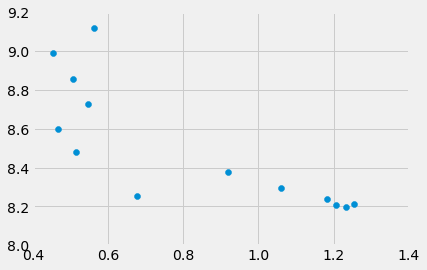

In [21]:
plt.scatter(food_price_death_rate['food_price'],food_price_death_rate['death_rate_value'])
plt.show()

### Normalization

In [22]:
date = food_price_death_rate.index

In [23]:
scaler = MinMaxScaler()

In [24]:
food_price_death_rate = scaler.fit_transform(food_price_death_rate)
food_price_death_rate = pd.DataFrame(food_price_death_rate)
food_price_death_rate['date'] = date
food_price_death_rate.set_index('date', inplace=True)
food_price_death_rate.columns = ['food_price', 'death_rate_value']
food_price_death_rate.head()

,food_price,death_rate_value
date,,
2008-01-01,0.138512,1.000000
2009-01-01,0.000000,0.861505
2010-01-01,0.066530,0.718648
2011-01-01,0.117426,0.574700
2012-01-01,0.019321,0.435115


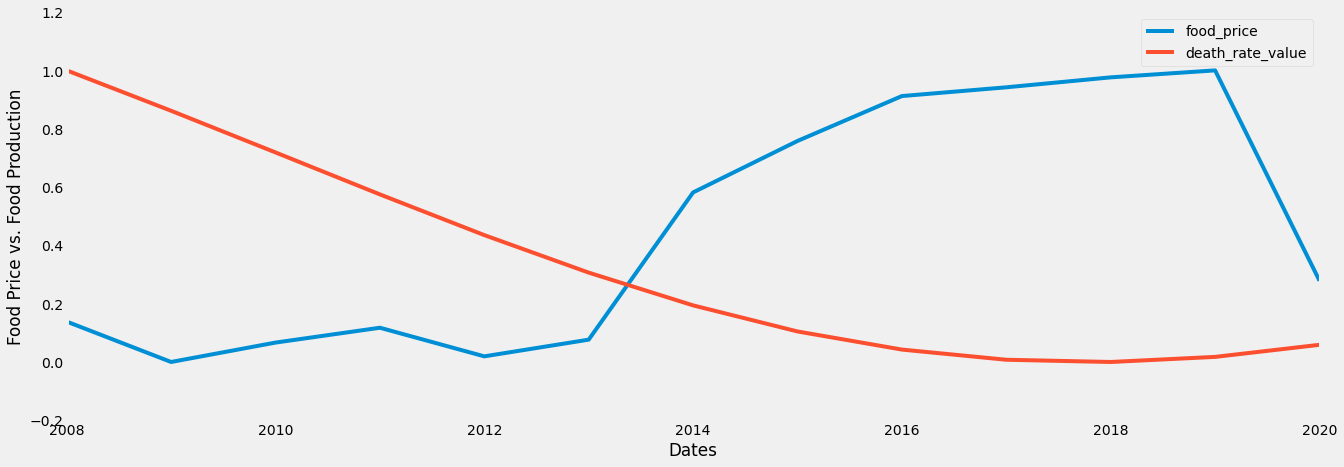

In [25]:
line_ax = food_price_death_rate.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Food Production')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is negative relation between Food Price and Food Production</span>